In [104]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn


def distance_squared(a, b):
    if a.shape[-1] == b.shape[-1]:
        return np.sum((b - a)**2, axis=-1)


class KNNClassifier:
    def __init__(self, k=5):
        self.k = k
        self.X_train = np.array([])
        self.y_train = np.array([])
        self.labels = np.array([])

    def distances(A, B):
        # no real reason not to use distance squared, it's faster computationally.
        return distance_squared(A[:, None, :], B[None, :, :])

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        self.labels = np.unique(y)

    def predict(self, X):
        results = self.predict_proba(X)
        maxes = np.argmax(results["probs"], axis=1)
        labels = (results["labels"])[maxes]
        return labels

    # returns dictionary with labels <---> indexes, and the actual results
    # uses lots of numpy shenanigans
    def predict_proba(self, X):
        points_distances = KNNClassifier.distances(self.X_train, X)
        train_indices = np.argpartition(points_distances, kth=self.k, axis=0)
        labeled_and_cut = ((self.y_train[train_indices]).T)[:,:self.k]
        modified_labeled = labeled_and_cut[:, :, None]
        modified_labels = self.labels[None, None, :]
        probs = (np.sum(modified_labeled == modified_labels, axis=1))/self.k
        return {"labels": self.labels, "probs": probs}

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

1.0


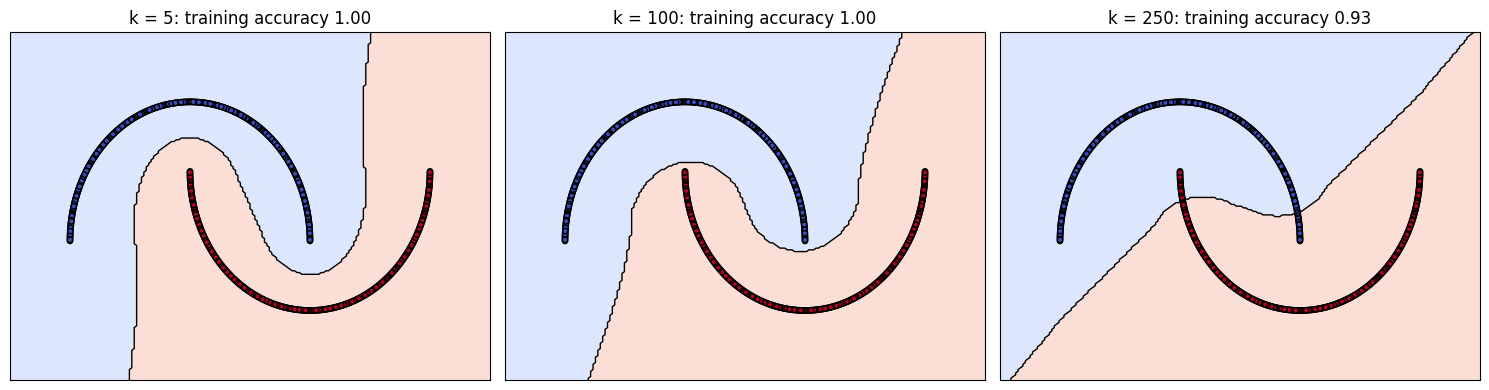

In [105]:
model = KNNClassifier(k=137)
N = 1000
test_amount = 0.2
X_tr, y_tr = sklearn.datasets.make_moons(int((1 - test_amount)*N), random_state=1)
X_te, y_te = sklearn.datasets.make_moons(N - int((1 - test_amount)*N), random_state=2)


model.fit(X_tr, y_tr) # X: N x n array, y: N labels
model.predict(X_te) # one label per row of X_new
model.predict_proba(X_te) # per row: the fraction of neighbours in each class
print(model.score(X_te, y_te)) # the accuracy


# rest of cell generated by AI and touched up by me, didnt feel necessary to learn matplotlib area plotting.
pad = 0.5
xs = np.linspace(X_tr[:, 0].min() - pad, X_tr[:, 0].max() + pad, 200)
ys = np.linspace(X_tr[:, 1].min() - pad, X_tr[:, 1].max() + pad, 200)
xx, yy = np.meshgrid(xs, ys)
grid = np.column_stack([xx.ravel(), yy.ravel()])  # (40000, 2)

# ---- plot ----
ks = [5, 100, 250]
fig, axes = plt.subplots(1, len(ks), figsize=(15, 4))
for ax, k in zip(axes, ks):
    model = KNNClassifier(k=k)
    model.fit(X_tr, y_tr)
    Z = model.predict(grid).reshape(xx.shape)
    acc = model.score(X_te, y_te)

    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.3)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1)
    ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", edgecolors="k", s=15)
    ax.set_title(f"k = {k}: training accuracy {acc:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

chose wine cuz seemed most interesting

In [115]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

wine = sklearn.datasets.load_wine()
X_w = wine.data
y_w = wine.target
feature_names = list(wine.feature_names)

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(X_w, y_w, test_size=0.3, stratify=y_w, random_state=42)

scaler_w = StandardScaler()
scaler_w.fit(X_train_w)                           # learn means and stds from the TRAINING data only
X_train_w_s = scaler_w.transform(X_train_w)
X_test_w_s = scaler_w.transform(X_test_w)         # the same means and stds, applied to the test data

In [ ]:
dumbKnn = KNNClassifier(k=X_train_w_s.shape[0]-1)
dumbKnn.fit(X_train_w_s, y_train_w)

regression = LogisticRegression()
regression.fit(X_train_w_s, y_train_w)

goodKnn = KNNClassifier(k=13)
goodKnn.fit(X_train_w_s, y_train_w)

print(f"dumb knn score: {dumbKnn.score(X_test_w_s, y_test_w)}")
print(f"logistic regression score: {regression.score(X_test_w_s, y_test_w)}")
print(f"good knn score: {goodKnn.score(X_test_w_s, y_test_w)}") 

dumb knn score: 0.3888888888888889
logistic regression score: 0.9814814814814815
good knn score: 0.9814814814814815


kNN seems to work somewhat fine, but the need to manually tune k makes it less favorable to Logistic Regression, which consistently and automatically tunes itself. it is better than simply picking the most common class.